# CSC2042S
## Assignment 3: Neural Networks
### Total marks: 30


#### Assignment goal: Optimisation of a Neural Network for Image Classification

This Jupyter Notebook will guide you through building a neural network, understanding the training process including backpropagation), and experimentally discovering how hyperparameters impact performance.

**Dataset: Fashion-MNIST** - A collection of 70,000 grayscale images of clothing items, perfect for testing your models.
https://www.kaggle.com/datasets/zalando-research/fashionmnist

## Part 1: Setup and Data Loading

* Import necessary libraries, such as ``torch``, ``torch.nn``, ``torchvision.transforms``, ``matplotlib.pyplot``, etc.

* Load the dataset and transform the dataset (convert to tensors, normalise). Load the Fashion_mNIST dataset into ``DataLoader`` objects for training and validation.

Data partitioning: Download the 60,000-image training dataset and split it into:
50,000 samples for training.
10,000 samples for validation.
Take into account Normalisation.


In [15]:
#libaries 

import numpy as np 
import pandas as pd 
import torch 
import torch.nn as nn
import torch.optim as optim 
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split 
from torchvision import datasets, transforms
import copy 
import itertools
# reproduce 

torch.manual_seed(42)
np.random.seed(42)


# image to tensor + normalise
raw = datasets.FashionMNIST(root="./data", train=True, download=True)
data = raw.data.float() / 255      # all pixels, scaled to 0-1
print(data.mean(), data.std())    



transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.2860,), (0.3530,))])


class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

tensor(0.2860) tensor(0.3530)


In [3]:
#load data 

# load training set
full_train = datasets.FashionMNIST(root="./data", train = True, download= True, transform = transform)

#split into training and validation set
train_set, val_set = random_split(full_train, [50000,10000], generator = torch.Generator().manual_seed(42))

#dataloaders
train_loader = DataLoader(train_set, batch_size=64, shuffle= True)
val_loader = DataLoader(val_set, batch_size =64, shuffle=False)


#check if it worked
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)


torch.Size([64, 1, 28, 28]) torch.Size([64])


## Part 2: Building and Training a Baseline Model [5 Marks]

Before we can optimise a model, we need a baseline to compare against. We will build a simple, standard neural network and train it with default settings.

**Define the Network Architecture**
Define a PyTorch class for your neural network that inherits from ``nn.Module``. Your model should be a simple Multi-Layer Perceptron (MLP) with the following architecture:

* Input Layer (a flattening layer).

* Hidden Layer 1: 128 neurons, ReLU activation.

* Hidden Layer 2: 64 neurons, ReLU activation.

* Output Layer: 10 neurons (one for each class).

**Training Loop**
Complete the provided ``train_model`` function. You will need to fill in the essential steps of the training process within the loop. This is where you will implement the logic for the forward pass, loss calculation, backpropagation, and weight updates.

**Train the Baseline Model**
Create an instance of your model, define a loss function, and an optimiser. Train your model for 10 epochs and record its final accuracy on the validation set. This is your baseline accuracy.

In [13]:
# Define Network Architecture [2 Marks]
class FashionnMLP(nn.Module, ):

    def __init__(self, dropout_p = 0.0):
        
        super().__init__()
    #turn [64, 1, 28, 28] into [64, 784]

        self.flatten =  nn.Flatten() 
        #hidden layer 1
        self.hl1 = nn.Linear(784,128)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_p)

#hidden 2
        self.hl2 = nn.Linear(128,64)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_p)
#output layer
        self.hl3 = nn.Linear(64,10)

    def forward (self,x):

        x = self.flatten(x)

        h1 = self.drop1(self.act1(self.hl1(x)))
        h2 = self.drop2(self.act2(self.hl2(h1)))
#return 10 scores per image
        return self.hl3(h2)






In [6]:
#test if it works 
model = FashionnMLP()
print(model(images).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([64, 10])
109386


In [10]:
# Updated Training and Evaluation skeleton [3 Marks]
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    """
    Trains a model and validates it each epoch.
    Returns: A dictionary containing lists of training loss, validation loss,
             and validation accuracy for each epoch.
    """
    # Data structure to store metrics
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    print("Starting Training...")
    for epoch in range(epochs):
        model.train() # Set model to training mode
        running_train_loss = 0.0
        for images, labels in train_loader:
            # 1. Forward Pass, Loss, Backward Pass, and Weight Update
            
            # clear old grad
            optimizer.zero_grad()
            outputs = model(images)
            #loss
            loss = criterion(outputs, labels)

            #backprop
            loss.backward()

            optimizer.step()
            running_train_loss = running_train_loss + loss.item()* images.size(0)

            

        # Calculate and store average training loss for the epoch
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        history['train_loss'].append(epoch_train_loss)

        # 2. Validation Phase
        model.eval() # Set model to evaluation mode
        running_val_loss = 0.0
        correct_predictions = 0
        total_predictions = 0

        with torch.no_grad(): # Disable gradient calculations
            for images, labels in val_loader:
                # Make predictions and calculate validation loss
                
                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss = running_val_loss + loss.item()*images.size(0)
                predicted = outputs.argmax(dim=1)

                
                # Calculate accuracy
                
                #.sum() will count the number Trues
                correct_predictions = correct_predictions + (predicted ==labels).sum().item()
                total_predictions = total_predictions + labels.size(0)

        # Calculate and store average validation loss and accuracy
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct_predictions / total_predictions
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    print("Finished Training")
    return history

In [11]:
# Train the Baseline Model [3 Marks]
# SGD at aplha 0.1 using 10 epochs

torch.manual_seed(42)
baseline_model = FashionnMLP()

baseline_criterion = nn.CrossEntropyLoss()
baseline_optimiser = optim.SGD(baseline_model.parameters(), lr=0.01)

baseline_history = train_model(baseline_model, train_loader, val_loader, baseline_criterion, baseline_optimiser, epochs=10)

baseline_acc = baseline_history['val_acc'][-1]
print(f"Baseline final validation accuracy: {baseline_acc:.4f}")



Starting Training...
Epoch 1/10 - Train Loss: 0.9518, Val Loss: 0.6774, Val Acc: 0.7552
Epoch 2/10 - Train Loss: 0.5300, Val Loss: 0.5123, Val Acc: 0.8232
Epoch 3/10 - Train Loss: 0.4687, Val Loss: 0.4832, Val Acc: 0.8242
Epoch 4/10 - Train Loss: 0.4370, Val Loss: 0.4455, Val Acc: 0.8383
Epoch 5/10 - Train Loss: 0.4145, Val Loss: 0.4292, Val Acc: 0.8475
Epoch 6/10 - Train Loss: 0.3977, Val Loss: 0.4452, Val Acc: 0.8352
Epoch 7/10 - Train Loss: 0.3839, Val Loss: 0.4335, Val Acc: 0.8402
Epoch 8/10 - Train Loss: 0.3726, Val Loss: 0.3998, Val Acc: 0.8575
Epoch 9/10 - Train Loss: 0.3614, Val Loss: 0.4597, Val Acc: 0.8234
Epoch 10/10 - Train Loss: 0.3521, Val Loss: 0.3900, Val Acc: 0.8586
Finished Training
Baseline final validation accuracy: 0.8586


## Part 3: Hyperparameter Optimisation Experiment [10 Marks]

Remember the definition of hyperparameters - they are external configuration variables set before training begins, controlling the model's structure and the learning process itself.
The goal is to find the set of the values that beats the baseline accuracy.

**Design and run your experiment**
Choose **three** from the following categories of hyperparameters to investigate:
* Learning Processes
* Regularisation/Architecture
  

Write a script (e.g., using nested loops) that systematically trains and evaluates a new model for each combination of the hyperparameters you have chosen. Store the final validation accuracy for each run in a data structure.

In [14]:
# Hyperparameter Optimisation Experiment [15 Marks]

learn_rates  = [0.001, 0.01, 0.1]
optimisers = ["SGD", "Adam"]
dropout_rates = [0.0, 0.3]
def build_optimser(name, parms, lr):

    if name == "SGD":
        return optim.SGD(parms, lr=lr)
    return optim.Adam(parms, lr= lr)

results =[]
best_acc = -1
best_state = None

for lr, optimser, drop in itertools.product(learn_rates, optimisers, dropout_rates):
    
    print(f"\n lr={lr}  optimizer={optimser}  dropout={drop} ") 

    torch.manual_seed(42)
    model = FashionnMLP(dropout_p= drop)
    criterion = nn.CrossEntropyLoss()
    optimser = build_optimser(optimser, model.parameters(), lr)

    history = train_model(model, train_loader, val_loader, criterion, optimser, epochs =10)

    final_acc = history["val_acc"][-1]
    results.append({"learning_rate": lr, "optimizer": optimser, "dropout": drop,"final_val_acc": final_acc, "history": history})



    if final_acc> best_acc:
        best_acc =final_acc
        best_state = copy.deepcopy(model.state_dict())
        best_cfg = (lr,optimser, drop)


    print("\nBest Configuration (lr, optimiser, dropout):", best_cfg, round(best_acc, 4))




=== lr=0.001, optimizer=SGD, dropout=0.0 ===
Starting Training...
Epoch 1/10 - Train Loss: 2.0988, Val Loss: 1.8284, Val Acc: 0.4665
Epoch 2/10 - Train Loss: 1.5001, Val Loss: 1.2149, Val Acc: 0.6693
Epoch 3/10 - Train Loss: 1.0509, Val Loss: 0.9380, Val Acc: 0.7159
Epoch 4/10 - Train Loss: 0.8571, Val Loss: 0.8070, Val Acc: 0.7370
Epoch 5/10 - Train Loss: 0.7559, Val Loss: 0.7329, Val Acc: 0.7462
Epoch 6/10 - Train Loss: 0.6951, Val Loss: 0.6868, Val Acc: 0.7550
Epoch 7/10 - Train Loss: 0.6550, Val Loss: 0.6542, Val Acc: 0.7631
Epoch 8/10 - Train Loss: 0.6251, Val Loss: 0.6294, Val Acc: 0.7737
Epoch 9/10 - Train Loss: 0.6018, Val Loss: 0.6072, Val Acc: 0.7835
Epoch 10/10 - Train Loss: 0.5823, Val Loss: 0.5896, Val Acc: 0.7887
Finished Training

Best Configuration (lr, optimiser, dropout): (0.001, SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0

In [ ]:
#best config

best_cfg = (0.001, "Adam", 0.0)

## Part 4: Analysis and Report  [10 Marks]
In this final section, you will analyse the results of your experiment and report your findings.

* Present your experimental results in a well-formatted table (e.g., a Pandas DataFrame) showing the combination of hyperparameters and the final validation accuracy for each run. [2 Marks]
* Create at least two visualisations to help interpret your results: [4 Marks]
    * Hyperparameter Impact: Create a bar chart or heatmap that clearly compares the performance of your different hyperparameter combinations.
    * Loss Curves. Plot the training and validation loss curves (loss vs. epochs) for your baseline model and your single best-performing model on the same graph. This is crucial for comparing model convergence and overfitting.
    * Confusion Matrix. Generate and display a confusion matrix for your best model's predictions on the validation set. This will help you see which specific clothing items are being confused.
* Interpret your results. [4 Marks]
  * Answer the following questions concisely, using evidence from your table and plots to support your claims:
    * Best vs. Baseline: Which combination of hyperparameters produced the best model? How much did it improve upon the baseline accuracy?
    * Hyperparameter Influence: Which hyperparameter had the most significant impact on performance? Explain why you think certain values worked better than others.
    * Overfitting Analysis: By comparing the loss curves of your baseline and best models, analyze the degree of overfitting. Did your hyperparameter tuning help mitigate overfitting? How can you tell from the plot?
    * Error Analysis: Look at your confusion matrix. Identify two classes that the model frequently confuses. Propose a reason for this confusion by considering the visual characteristics of the items in those classes.

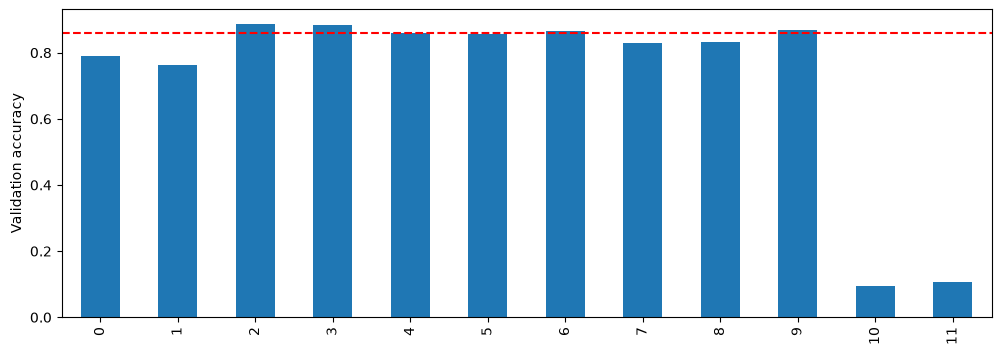

In [16]:
# results 
#table
df = pd.DataFrame(results)[["learning_rate", "optimizer", "dropout", "final_val_acc"]]
df.sort_values("final_val_acc", ascending=False)

#bar chart 
df.plot.bar(x=None, y="final_val_acc", figsize=(12, 4), legend=False)
plt.axhline(baseline_acc, color="red", linestyle="--", label="Baseline")
plt.ylabel("Validation accuracy")
plt.show()




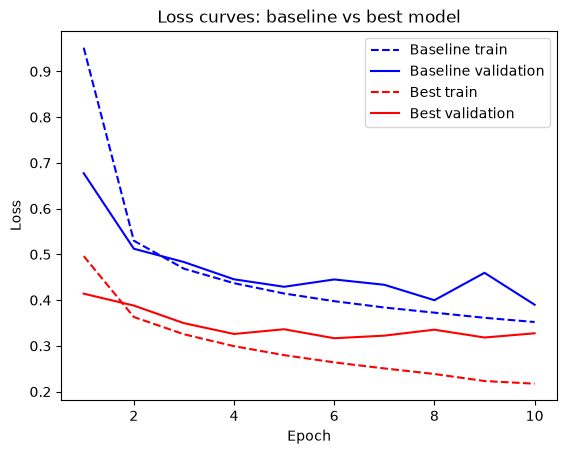

In [17]:
#Loss curves
best_run = max(results, key=lambda r: r["final_val_acc"])
best_history = best_run["history"]

epochs = range(1, 11)
plt.plot(epochs, baseline_history["train_loss"], "b--", label="Baseline train")
plt.plot(epochs, baseline_history["val_loss"], "b-", label="Baseline validation")
plt.plot(epochs, best_history["train_loss"], "r--", label="Best train")
plt.plot(epochs, best_history["val_loss"], "r-", label="Best validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss curves: baseline vs best model")
plt.legend()
plt.show()


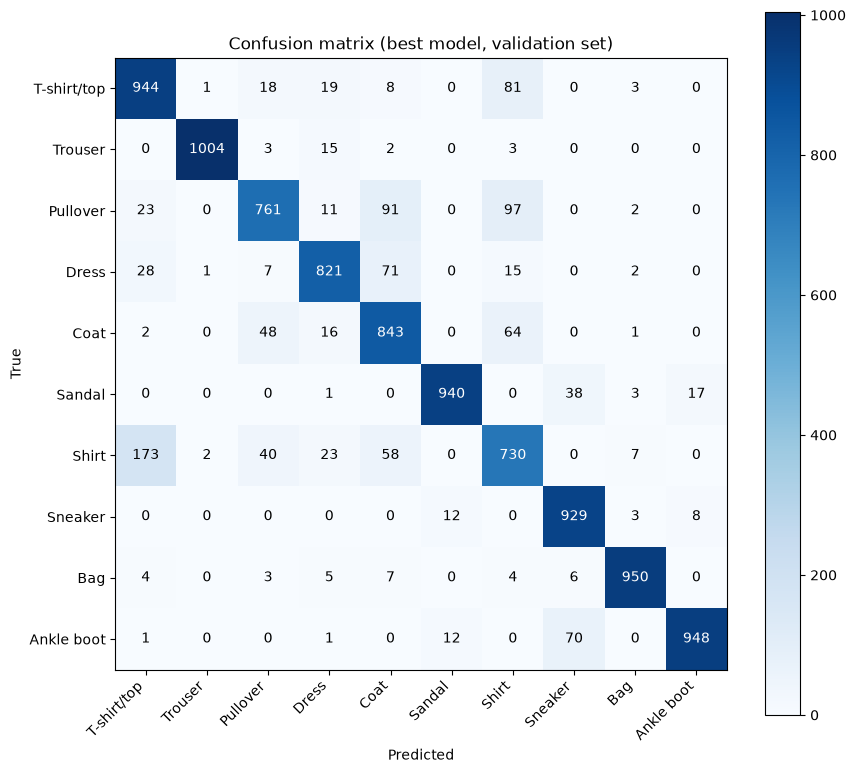

In [ ]:
#confusion matrix

# rebuild the best model and load its weights
best_model = FashionnMLP(dropout_p=0.0)
best_model.load_state_dict(best_state)
best_model.eval()

#collect the predictions and true labels
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        all_preds.append(best_model(images).argmax(dim=1))
        all_labels.append(labels)
preds = torch.cat(all_preds)
true = torch.cat(all_labels)

#count each true, predicted pair into a 10x10 table
cm = torch.bincount(true * 10 + preds, minlength=100).reshape(10, 10).numpy()

# Plot it
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (best model, validation set)")
plt.tight_layout()
plt.show()